In [8]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)

Project root: d:\PG Study material\Foundations of AI\LSTM_explainer


In [9]:
ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "artifacts"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Artifact directory:", ARTIFACT_DIR)

Artifact directory: d:\PG Study material\Foundations of AI\LSTM_explainer\data\processed\artifacts


In [11]:
import numpy as np
import pandas as pd
import torch
import json
import joblib

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

ARTIFACT_DIR = PROJECT_ROOT / "data" / "processed" / "artifacts"

# Load configuration
with open(ARTIFACT_DIR / "config.json", "r") as file:
    config = json.load(file)

# Load scaler
scaler = joblib.load(
    ARTIFACT_DIR / "temperature_scaler.pkl"
)

# Load city mapping
with open(ARTIFACT_DIR / "city_to_id.json", "r") as file:
    city_to_id = json.load(file)

# Load sequences
data = np.load(ARTIFACT_DIR / "weather_sequences.npz")

X_train = data["X_train"]
y_train = data["y_train"]
city_train = data["city_train"]

X_val = data["X_val"]
y_val = data["y_val"]
city_val = data["city_val"]

X_test = data["X_test"]
y_test = data["y_test"]
city_test = data["city_test"]

print("Artifacts loaded successfully!")
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)
print("Number of cities:", len(city_to_id))

Artifacts loaded successfully!
Training shape: (85750, 30, 1)
Validation shape: (18700, 30, 1)
Testing shape: (18750, 30, 1)
Number of cities: 50


In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [13]:
import torch
import torch.nn as nn


class WeatherLSTM(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        num_cities,
        embedding_dim
    ):
        super(WeatherLSTM, self).__init__()

        # City embedding
        self.city_embedding = nn.Embedding(
            num_cities,
            embedding_dim
        )

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        # Fully connected prediction layer
        self.fc = nn.Linear(
            hidden_size + embedding_dim,
            1
        )

    def forward(self, x, city_id):

        # Pass temperature sequence through LSTM
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Get final hidden state
        final_hidden = hidden_state[-1]

        # Get city embedding
        city_vector = self.city_embedding(city_id)

        # Combine both representations
        combined = torch.cat(
            (final_hidden, city_vector),
            dim=1
        )

        # Predict next-day temperature
        prediction = self.fc(combined)

        return prediction

In [14]:
INPUT_SIZE = 1
HIDDEN_SIZE = 64
NUM_CITIES = len(city_to_id)
EMBEDDING_DIM = 8

model = WeatherLSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_cities=NUM_CITIES,
    embedding_dim=EMBEDDING_DIM
)

model = model.to(device)

print(model)

WeatherLSTM(
  (city_embedding): Embedding(50, 8)
  (lstm): LSTM(1, 64, batch_first=True)
  (fc): Linear(in_features=72, out_features=1, bias=True)
)


In [15]:
# Convert one batch into tensors
sample_X = torch.tensor(
    X_train[:128],
    dtype=torch.float32
).to(device)

sample_city = torch.tensor(
    city_train[:128],
    dtype=torch.long
).to(device)

# Run a forward pass
with torch.no_grad():
    sample_prediction = model(sample_X, sample_city)

print("Input shape:", sample_X.shape)
print("City ID shape:", sample_city.shape)
print("Prediction shape:", sample_prediction.shape)
print("GPU:", next(model.parameters()).device)

Input shape: torch.Size([128, 30, 1])
City ID shape: torch.Size([128])
Prediction shape: torch.Size([128, 1])
GPU: cuda:0


In [16]:
# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [17]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 128

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(city_train, dtype=torch.long),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(city_val, dtype=torch.long),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(city_test, dtype=torch.long),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 670
Validation batches: 147
Testing batches: 147


In [18]:
import copy
from pathlib import Path

EPOCHS = 30
PATIENCE = 5

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = MODEL_DIR / "best_weather_lstm.pth"


for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss = 0.0

    for X_batch, city_batch, y_batch in train_loader:

        X_batch = X_batch.to(device, non_blocking=True)
        city_batch = city_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch, city_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_dataset)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for X_batch, city_batch, y_batch in val_loader:

            X_batch = X_batch.to(device, non_blocking=True)
            city_batch = city_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            predictions = model(X_batch, city_batch)

            loss = criterion(predictions, y_batch)

            val_loss += loss.item() * X_batch.size(0)

    val_loss /= len(val_dataset)

    # Record losses
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} "
        f"Validation Loss: {val_loss:.6f}"
    )

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(model.state_dict(), best_model_path)

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered!")
        break


print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Best model saved at:", best_model_path)

Epoch [1/30] Train Loss: 0.011054 Validation Loss: 0.001107
Epoch [2/30] Train Loss: 0.001005 Validation Loss: 0.000975
Epoch [3/30] Train Loss: 0.000886 Validation Loss: 0.000885
Epoch [4/30] Train Loss: 0.000780 Validation Loss: 0.000840
Epoch [5/30] Train Loss: 0.000693 Validation Loss: 0.000700
Epoch [6/30] Train Loss: 0.000632 Validation Loss: 0.000646
Epoch [7/30] Train Loss: 0.000596 Validation Loss: 0.000609
Epoch [8/30] Train Loss: 0.000571 Validation Loss: 0.000651
Epoch [9/30] Train Loss: 0.000565 Validation Loss: 0.000589
Epoch [10/30] Train Loss: 0.000557 Validation Loss: 0.000584
Epoch [11/30] Train Loss: 0.000552 Validation Loss: 0.000607
Epoch [12/30] Train Loss: 0.000554 Validation Loss: 0.000607
Epoch [13/30] Train Loss: 0.000558 Validation Loss: 0.000601
Epoch [14/30] Train Loss: 0.000553 Validation Loss: 0.000587
Epoch [15/30] Train Loss: 0.000554 Validation Loss: 0.000645
Early stopping triggered!

Training completed!
Best validation loss: 0.0005843851061408373
Bes

In [19]:
# Load the best validation checkpoint
model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

model.eval()

print("Best model checkpoint loaded!")

Best model checkpoint loaded!


In [20]:
all_predictions = []
all_actuals = []

model.eval()

with torch.no_grad():

    for X_batch, city_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)
        city_batch = city_batch.to(device)

        predictions = model(X_batch, city_batch)

        all_predictions.append(predictions.cpu())
        all_actuals.append(y_batch)

# Combine batches
predictions_scaled = torch.cat(all_predictions).numpy()
actuals_scaled = torch.cat(all_actuals).numpy()

print("Predictions shape:", predictions_scaled.shape)
print("Actual values shape:", actuals_scaled.shape)

Predictions shape: (18750, 1)
Actual values shape: (18750, 1)


In [21]:
predictions_celsius = scaler.inverse_transform(predictions_scaled)

actuals_celsius = scaler.inverse_transform(actuals_scaled)

print("First 10 predictions:")
for i in range(10):
    print(
        f"Actual: {actuals_celsius[i][0]:.2f}°C | "
        f"Predicted: {predictions_celsius[i][0]:.2f}°C"
    )

First 10 predictions:
Actual: 33.30°C | Predicted: 32.76°C
Actual: 33.70°C | Predicted: 33.04°C
Actual: 33.90°C | Predicted: 33.42°C
Actual: 33.90°C | Predicted: 33.63°C
Actual: 33.20°C | Predicted: 33.67°C
Actual: 33.40°C | Predicted: 33.12°C
Actual: 33.70°C | Predicted: 33.34°C
Actual: 34.50°C | Predicted: 33.62°C
Actual: 33.60°C | Predicted: 34.29°C
Actual: 33.30°C | Predicted: 33.53°C


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(
    actuals_celsius,
    predictions_celsius
)

rmse = np.sqrt(
    mean_squared_error(actuals_celsius, predictions_celsius)
)

r2 = r2_score(
    actuals_celsius,
    predictions_celsius
)

print("TEST RESULTS")
print("-------------------------")
print(f"MAE:  {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"R²:   {r2:.4f}")

TEST RESULTS
-------------------------
MAE:  1.0373 °C
RMSE: 1.4527 °C
R²:   0.9501


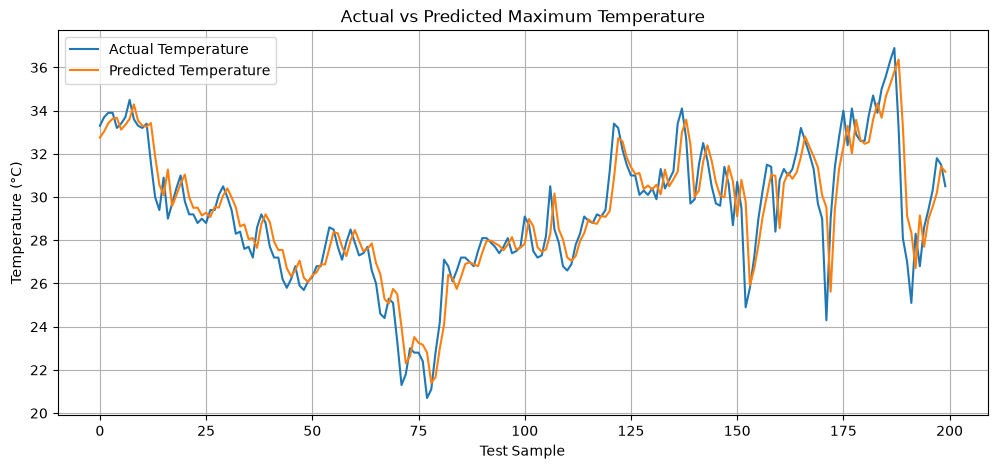

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actuals_celsius[:200],
    label="Actual Temperature"
)

plt.plot(
    predictions_celsius[:200],
    label="Predicted Temperature"
)

plt.title("Actual vs Predicted Maximum Temperature")
plt.xlabel("Test Sample")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reverse city mapping: ID -> city name
id_to_city = {
    int(city_id): city
    for city, city_id in city_to_id.items()
}

city_results = []

for city_id in np.unique(city_test):

    mask = city_test == city_id

    actual = actuals_celsius[mask].flatten()
    predicted = predictions_celsius[mask].flatten()

    city_results.append({
        "City": id_to_city[int(city_id)],
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

city_metrics = pd.DataFrame(city_results)

city_metrics = city_metrics.sort_values("MAE")

display(city_metrics.round(3))

,City,MAE,RMSE,R2
35,Port Blair,0.723,1.002,0.600
22,Kochi,0.752,0.959,0.626
32,Nashik,0.759,1.028,0.932
38,Pune,0.806,1.093,0.917
33,Panaji,0.833,1.135,0.703
37,Puducherry,0.841,1.133,0.871
30,Mysuru,0.861,1.155,0.781
45,Thiruvananthapuram,0.861,1.133,0.592
16,Imphal,0.870,1.215,0.810
29,Mumbai,0.870,1.252,0.778


In [25]:
# Predict tomorrow's temperature using the last observed temperature
baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)

# Convert to Celsius
baseline_predictions = scaler.inverse_transform(baseline_scaled)

# Calculate baseline metrics
baseline_mae = mean_absolute_error(
    actuals_celsius,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actuals_celsius, baseline_predictions)
)

baseline_r2 = r2_score(
    actuals_celsius,
    baseline_predictions
)

print("PERSISTENCE BASELINE")
print("-------------------------")
print(f"MAE:  {baseline_mae:.4f} °C")
print(f"RMSE: {baseline_rmse:.4f} °C")
print(f"R²:   {baseline_r2:.4f}")

print("\nLSTM MODEL")
print("-------------------------")
print(f"MAE:  {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"R²:   {r2:.4f}")

PERSISTENCE BASELINE
-------------------------
MAE:  1.0502 °C
RMSE: 1.4905 °C
R²:   0.9474

LSTM MODEL
-------------------------
MAE:  1.0373 °C
RMSE: 1.4527 °C
R²:   0.9501


In [26]:
mae_improvement = (
    (baseline_mae - mae) / baseline_mae
) * 100

print(f"MAE improvement over baseline: {mae_improvement:.2f}%")

MAE improvement over baseline: 1.23%


In [27]:
print("TOP 5 CITIES")
display(city_metrics.head(5).round(3))

print("\nBOTTOM 5 CITIES")
display(city_metrics.tail(5).round(3))

TOP 5 CITIES


,City,MAE,RMSE,R2
35,Port Blair,0.723,1.002,0.600
22,Kochi,0.752,0.959,0.626
32,Nashik,0.759,1.028,0.932
38,Pune,0.806,1.093,0.917
33,Panaji,0.833,1.135,0.703



BOTTOM 5 CITIES


,City,MAE,RMSE,R2
26,Ludhiana,1.287,1.702,0.939
1,Agra,1.343,1.845,0.924
11,Delhi,1.438,1.960,0.909
43,Srinagar,1.589,2.116,0.936
24,Leh,1.638,2.142,0.937


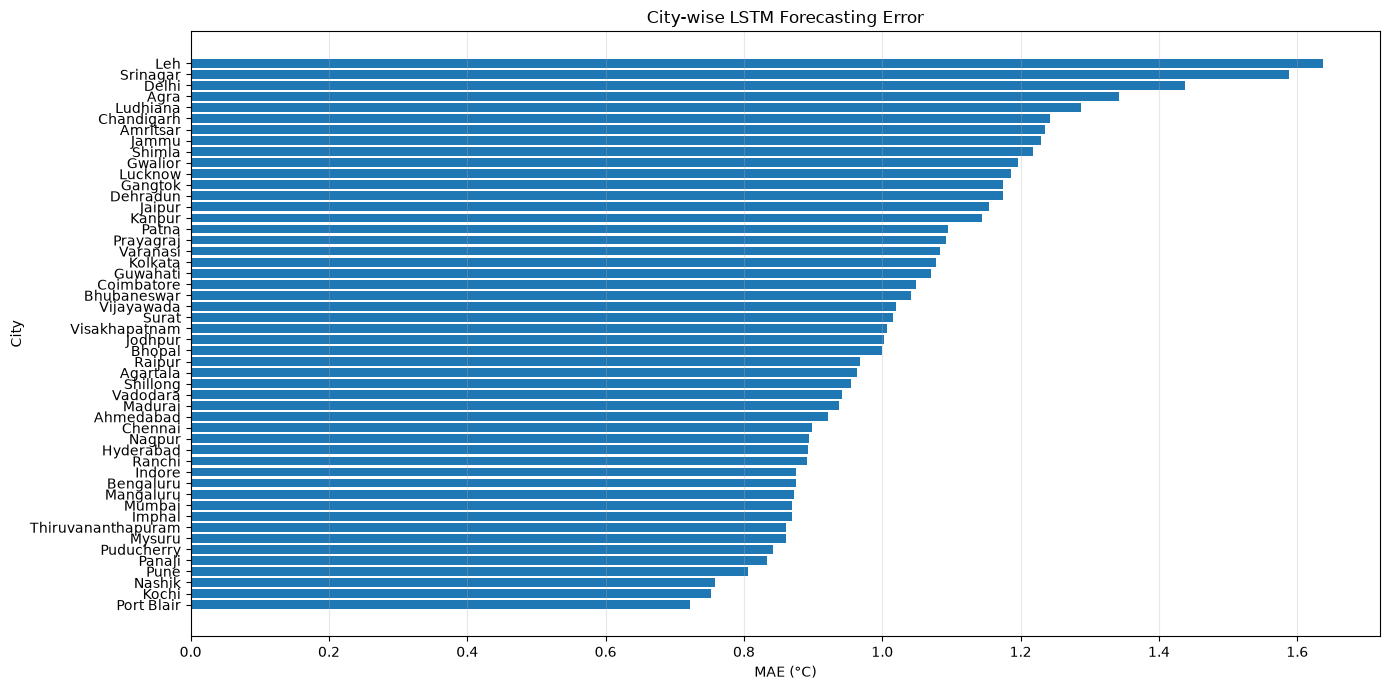

In [28]:
plt.figure(figsize=(14, 7))

sorted_metrics = city_metrics.sort_values("MAE")

plt.barh(
    sorted_metrics["City"],
    sorted_metrics["MAE"]
)

plt.xlabel("MAE (°C)")
plt.ylabel("City")
plt.title("City-wise LSTM Forecasting Error")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
import json

results = {
    "model": "Univariate City-Aware LSTM",
    "sequence_length": 30,
    "hidden_size": 64,
    "embedding_dim": 8,
    "epochs_trained": 15,
    "best_epoch": 10,
    "best_validation_loss": best_val_loss,
    "test_mae": float(mae),
    "test_rmse": float(rmse),
    "test_r2": float(r2),
    "baseline_mae": float(baseline_mae),
    "baseline_rmse": float(baseline_rmse),
    "baseline_r2": float(baseline_r2)
}

with open(MODEL_DIR / "version1_results.json", "w") as file:
    json.dump(results, file, indent=4)

print("Version 1 results saved!")

Version 1 results saved!
